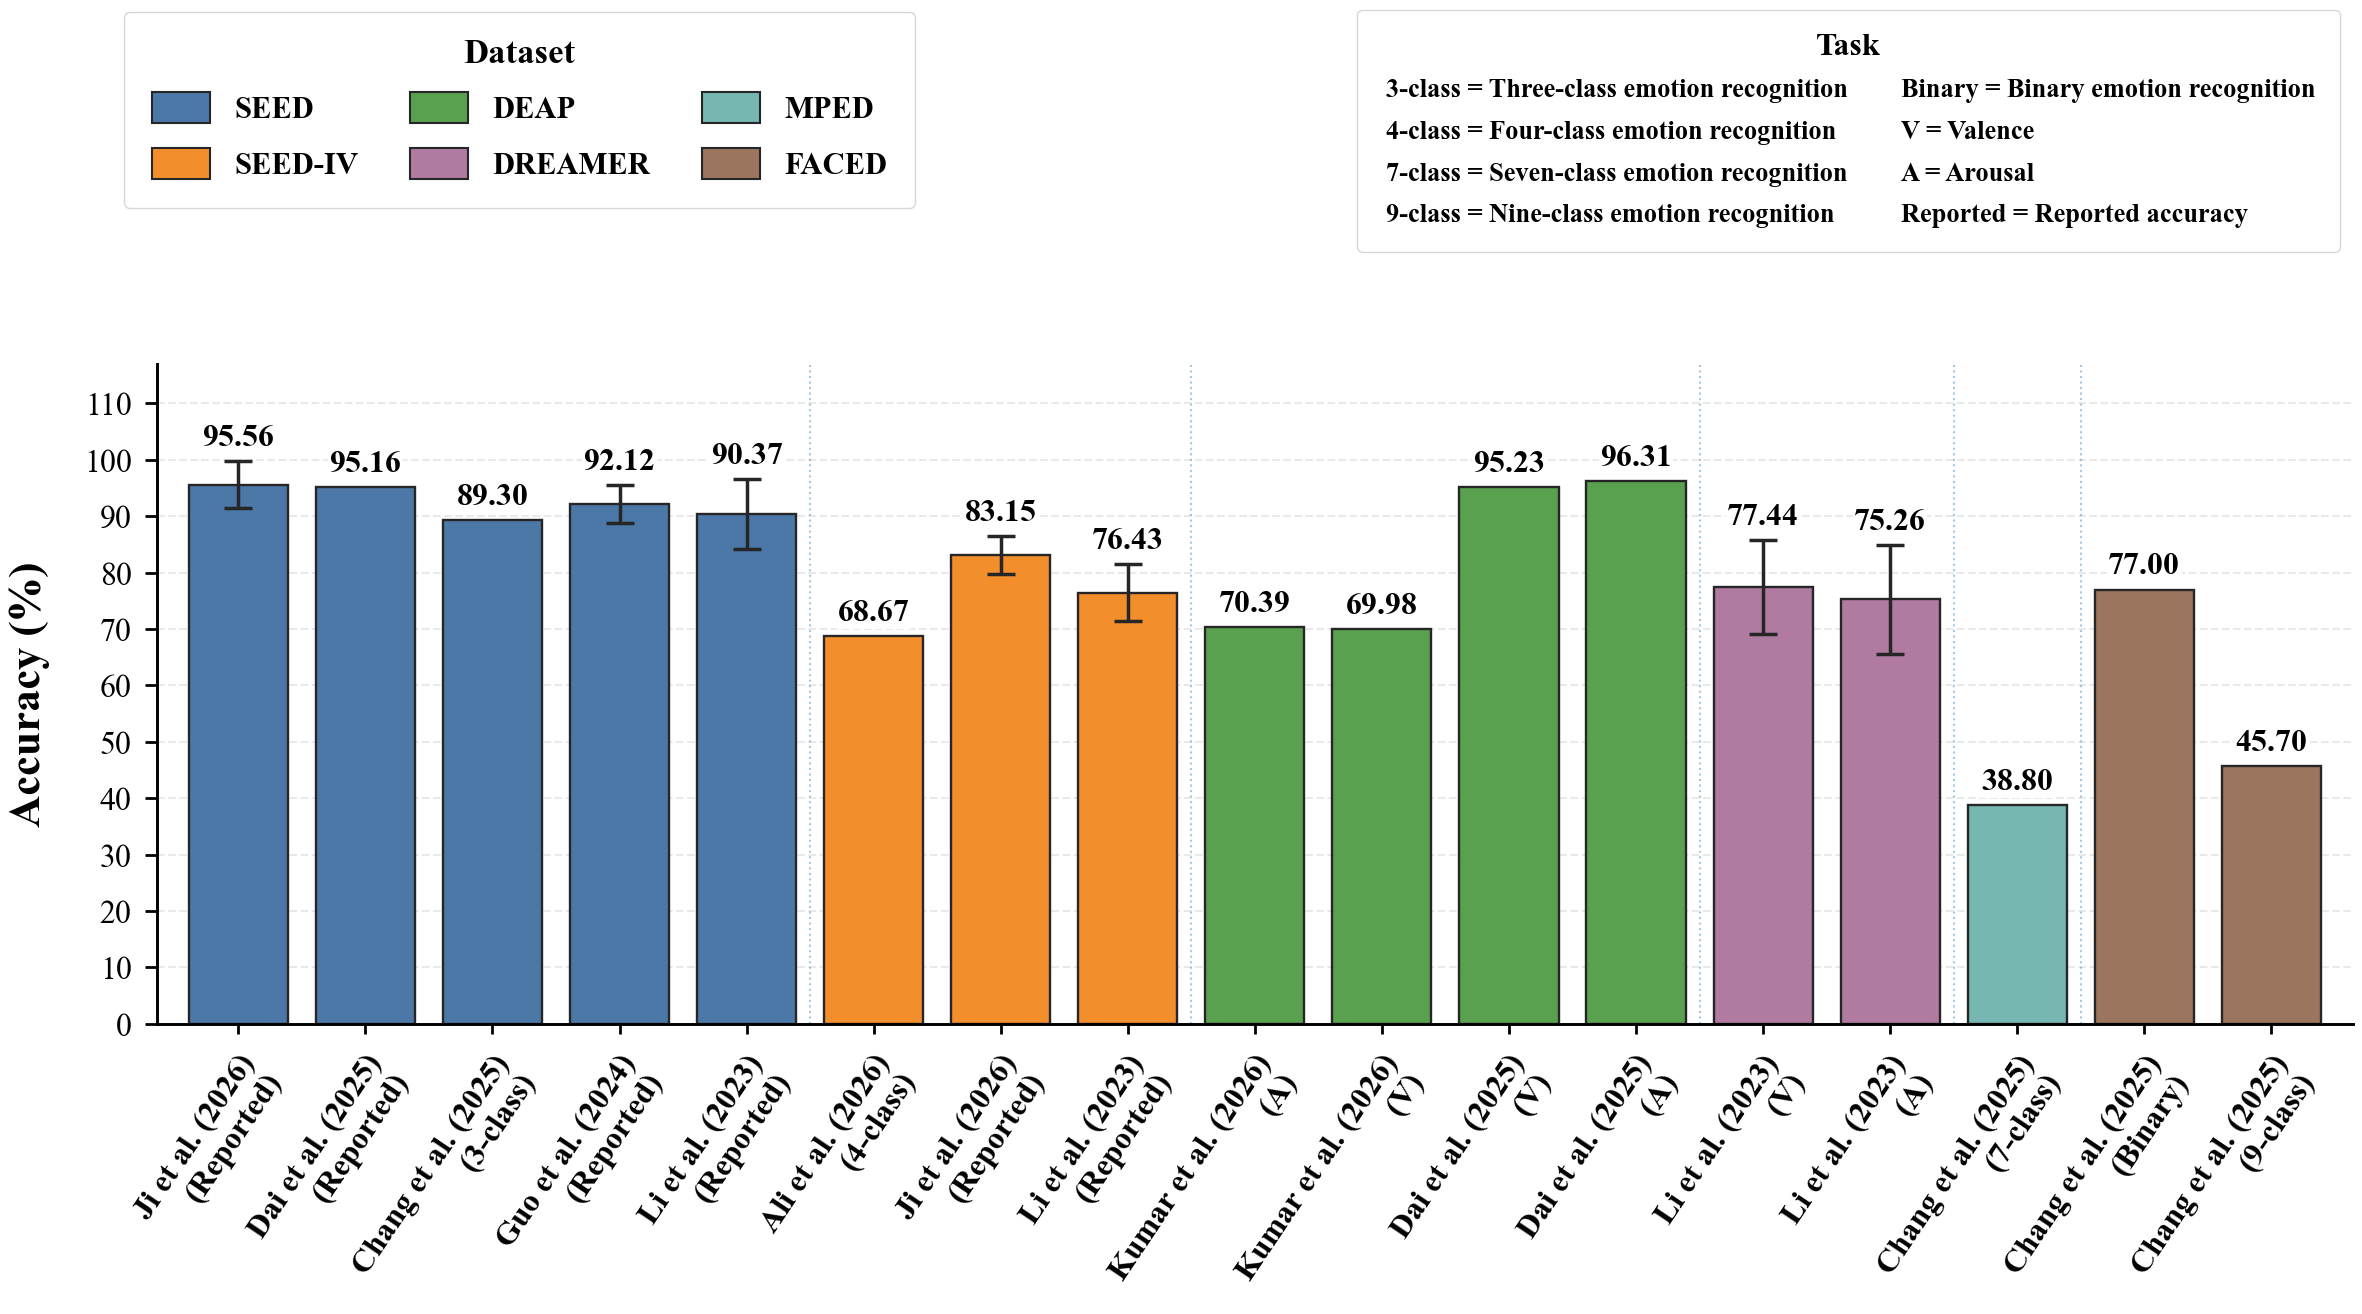

In [6]:
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

papers = [
    {
        "study": "Ali et al.",
        "year": 2026,
        "model": "CNN-LSTM-CBAM",
        "scores": [("SEED-IV", "4-class", 68.67, None)],
    },
    {
        "study": "Ji et al.",
        "year": 2026,
        "model": "NR-BA-BFE-Net",
        "scores": [
            ("SEED", "Reported", 95.56, 4.18),
            ("SEED-IV", "Reported", 83.15, 3.40),
        ],
    },
    {
        "study": "Kumar et al.",
        "year": 2026,
        "model": "QPC-EBM",
        "scores": [
            ("DEAP", "A", 70.39, None),
            ("DEAP", "V", 69.98, None),
        ],
    },
    {
        "study": "Dai et al.",
        "year": 2025,
        "model": "CLRA",
        "scores": [
            ("DEAP", "V", 95.23, None),
            ("DEAP", "A", 96.31, None),
            ("SEED", "Reported", 95.16, None),
        ],
    },
    {
        "study": "Chang et al.",
        "year": 2025,
        "model": "MSHCL",
        "scores": [
            ("SEED", "3-class", 89.30, None),
            ("MPED", "7-class", 38.80, None),
            ("FACED", "Binary", 77.00, None),
            ("FACED", "9-class", 45.70, None),
        ],
    },
    {
        "study": "Guo et al.",
        "year": 2024,
        "model": "FC-FAN",
        "scores": [("SEED", "Reported", 92.12, 3.32)],
    },
    {
        "study": "Li et al.",
        "year": 2023,
        "model": "STGATE",
        "scores": [
            ("SEED", "Reported", 90.37, 6.18),
            ("SEED-IV", "Reported", 76.43, 5.01),
            ("DREAMER", "V", 77.44, 8.40),
            ("DREAMER", "A", 75.26, 9.71),
        ],
    },
]

results = [
    {
        "study": paper["study"],
        "year": paper["year"],
        "model": paper["model"],
        "dataset": dataset,
        "task": task,
        "acc": acc,
        "std": std,
    }
    for paper in papers
    for dataset, task, acc, std in paper["scores"]
]

assert len(papers) == 7
assert len(results) == 17

# ============================================================
# DATASET GROUPS AND COLOURS
# ============================================================

dataset_order = ["SEED", "SEED-IV", "DEAP", "DREAMER", "MPED", "FACED"]

dataset_colors = {
    "SEED": "#4C78A8",
    "SEED-IV": "#F28E2B",
    "DEAP": "#59A14F",
    "DREAMER": "#B07AA1",
    "MPED": "#76B7B2",
    "FACED": "#9C755F",
}

ordered_results = [
    item
    for dataset in dataset_order
    for item in sorted(
        (r for r in results if r["dataset"] == dataset),
        key=lambda r: -r["year"],
    )
]

x_positions = np.arange(len(ordered_results))
accuracy = np.array([r["acc"] for r in ordered_results], dtype=float)
colors = [dataset_colors[r["dataset"]] for r in ordered_results]

labels = [f'{r["study"]} ({r["year"]})\n({r["task"]})' for r in ordered_results]

# ============================================================
# MATCHED FONT SETTINGS
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "font.size": 23,
        "axes.labelsize": 23,
        "xtick.labelsize": 23,
        "ytick.labelsize": 23,
        "legend.fontsize": 23,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(24, 15))

# ============================================================
# BAR CHART
# ============================================================

bars = ax.bar(
    x_positions,
    accuracy,
    width=0.78,
    color=colors,
    edgecolor="0.15",
    linewidth=1.7,
)

# ============================================================
# ERROR BARS
# ============================================================

known_std = [i for i, r in enumerate(ordered_results) if r["std"] is not None]

ax.errorbar(
    x_positions[known_std],
    accuracy[known_std],
    yerr=[ordered_results[i]["std"] for i in known_std],
    fmt="none",
    capsize=10,
    elinewidth=2.5,
    ecolor="0.15",
    capthick=2.5,
    zorder=4,
)

# ============================================================
# X-AXIS LABELS
# ============================================================

ax.set_xticks(x_positions)

ax.set_xticklabels(
    labels,
    rotation=56,
    ha="right",
    rotation_mode="anchor",
    fontsize=23,
    fontweight="bold",
    linespacing=1.18,
)

# ============================================================
# Y-AXIS AND GRID
# ============================================================

ax.set_ylabel(
    "Accuracy (%)",
    fontsize=32,
    fontweight="bold",
    labelpad=24,
)

ax.set_ylim(0, 117)
ax.set_yticks(np.arange(0, 111, 10))

ax.yaxis.grid(
    True,
    linestyle="--",
    linewidth=1.5,
    alpha=0.28,
)

ax.xaxis.grid(False)
ax.set_axisbelow(True)

# ============================================================
# SPINES
# ============================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.1)
ax.spines["bottom"].set_linewidth(2.1)

# ============================================================
# ACCURACY ANNOTATIONS
# ============================================================

for bar, record in zip(bars, ordered_results):
    error = record["std"] if record["std"] is not None else 0.0

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        record["acc"] + error + 1.5,
        f'{record["acc"]:.2f}',
        ha="center",
        va="bottom",
        fontsize=23,
        fontweight="bold",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "pad": 1.0,
            "alpha": 0.97,
        },
        zorder=10,
        clip_on=False,
    )

# ============================================================
# DATASET LEGEND -- ABOVE PLOT, TOP LEFT
# ============================================================

dataset_legend = fig.legend(
    handles=[
        Patch(
            facecolor=dataset_colors[d],
            edgecolor="0.15",
            linewidth=1.5,
            label=d,
        )
        for d in dataset_order
    ],
    title="Dataset",
    loc="upper left",
    bbox_to_anchor=(0.055, 0.985),
    ncol=3,
    frameon=True,
    prop={"size": 22, "weight": "bold"},
    borderpad=0.9,
    handlelength=1.9,
    handleheight=1.2,
    columnspacing=1.7,
    labelspacing=0.75,
)

dataset_legend.get_title().set_fontsize(25)
dataset_legend.get_title().set_fontweight("bold")

# ============================================================
# TASK LEGEND -- ABOVE PLOT, TOP RIGHT
# ============================================================

task_legend_labels = [
    "3-class = Three-class emotion recognition",
    "4-class = Four-class emotion recognition",
    "7-class = Seven-class emotion recognition",
    "9-class = Nine-class emotion recognition",
    "Binary = Binary emotion recognition",
    "V = Valence",
    "A = Arousal",
    "Reported = Reported accuracy",
]

task_legend = fig.legend(
    handles=[
        Line2D(
            [],
            [],
            linestyle="none",
            marker="",
            label=t,
        )
        for t in task_legend_labels
    ],
    title="Task",
    loc="upper right",
    bbox_to_anchor=(0.99, 0.985),
    ncol=2,
    frameon=True,
    prop={"size": 19, "weight": "bold"},
    borderpad=0.9,
    handlelength=0,
    handletextpad=0.2,
    columnspacing=1.8,
    labelspacing=0.65,
)

task_legend.get_title().set_fontsize(23)
task_legend.get_title().set_fontweight("bold")

# ============================================================
# TICKS
# ============================================================

ax.tick_params(
    axis="y",
    labelsize=23,
    width=2.0,
    length=9,
    pad=9,
)

ax.tick_params(
    axis="x",
    labelsize=23,
    width=2.0,
    length=7,
    pad=12,
)

# ============================================================
# DATASET SEPARATORS
# ============================================================

current_position = 0

for dataset in dataset_order[:-1]:
    current_position += sum(r["dataset"] == dataset for r in ordered_results)

    ax.axvline(
        current_position - 0.5,
        linewidth=1.5,
        linestyle=":",
        alpha=0.4,
    )

# ============================================================
# LAYOUT
# ============================================================

ax.margins(x=0.015)

plt.subplots_adjust(
    left=0.075,
    right=0.99,
    top=0.74,
    bottom=0.30,
)

# ============================================================
# SAVE FIGURE
# ============================================================

filename = "subject_independent_recent_7_studies"

plt.savefig(
    f"{filename}.pdf",
    bbox_inches="tight",
    pad_inches=0.20,
)

raster_dpi = int(os.environ.get("RASTER_DPI", "300"))

plt.savefig(
    f"{filename}.png",
    dpi=raster_dpi,
    bbox_inches="tight",
    pad_inches=0.20,
)

if os.environ.get("SKIP_TIFF") != "1":
    plt.savefig(
        f"{filename}.tiff",
        dpi=raster_dpi,
        bbox_inches="tight",
        pad_inches=0.20,
    )

plt.show()

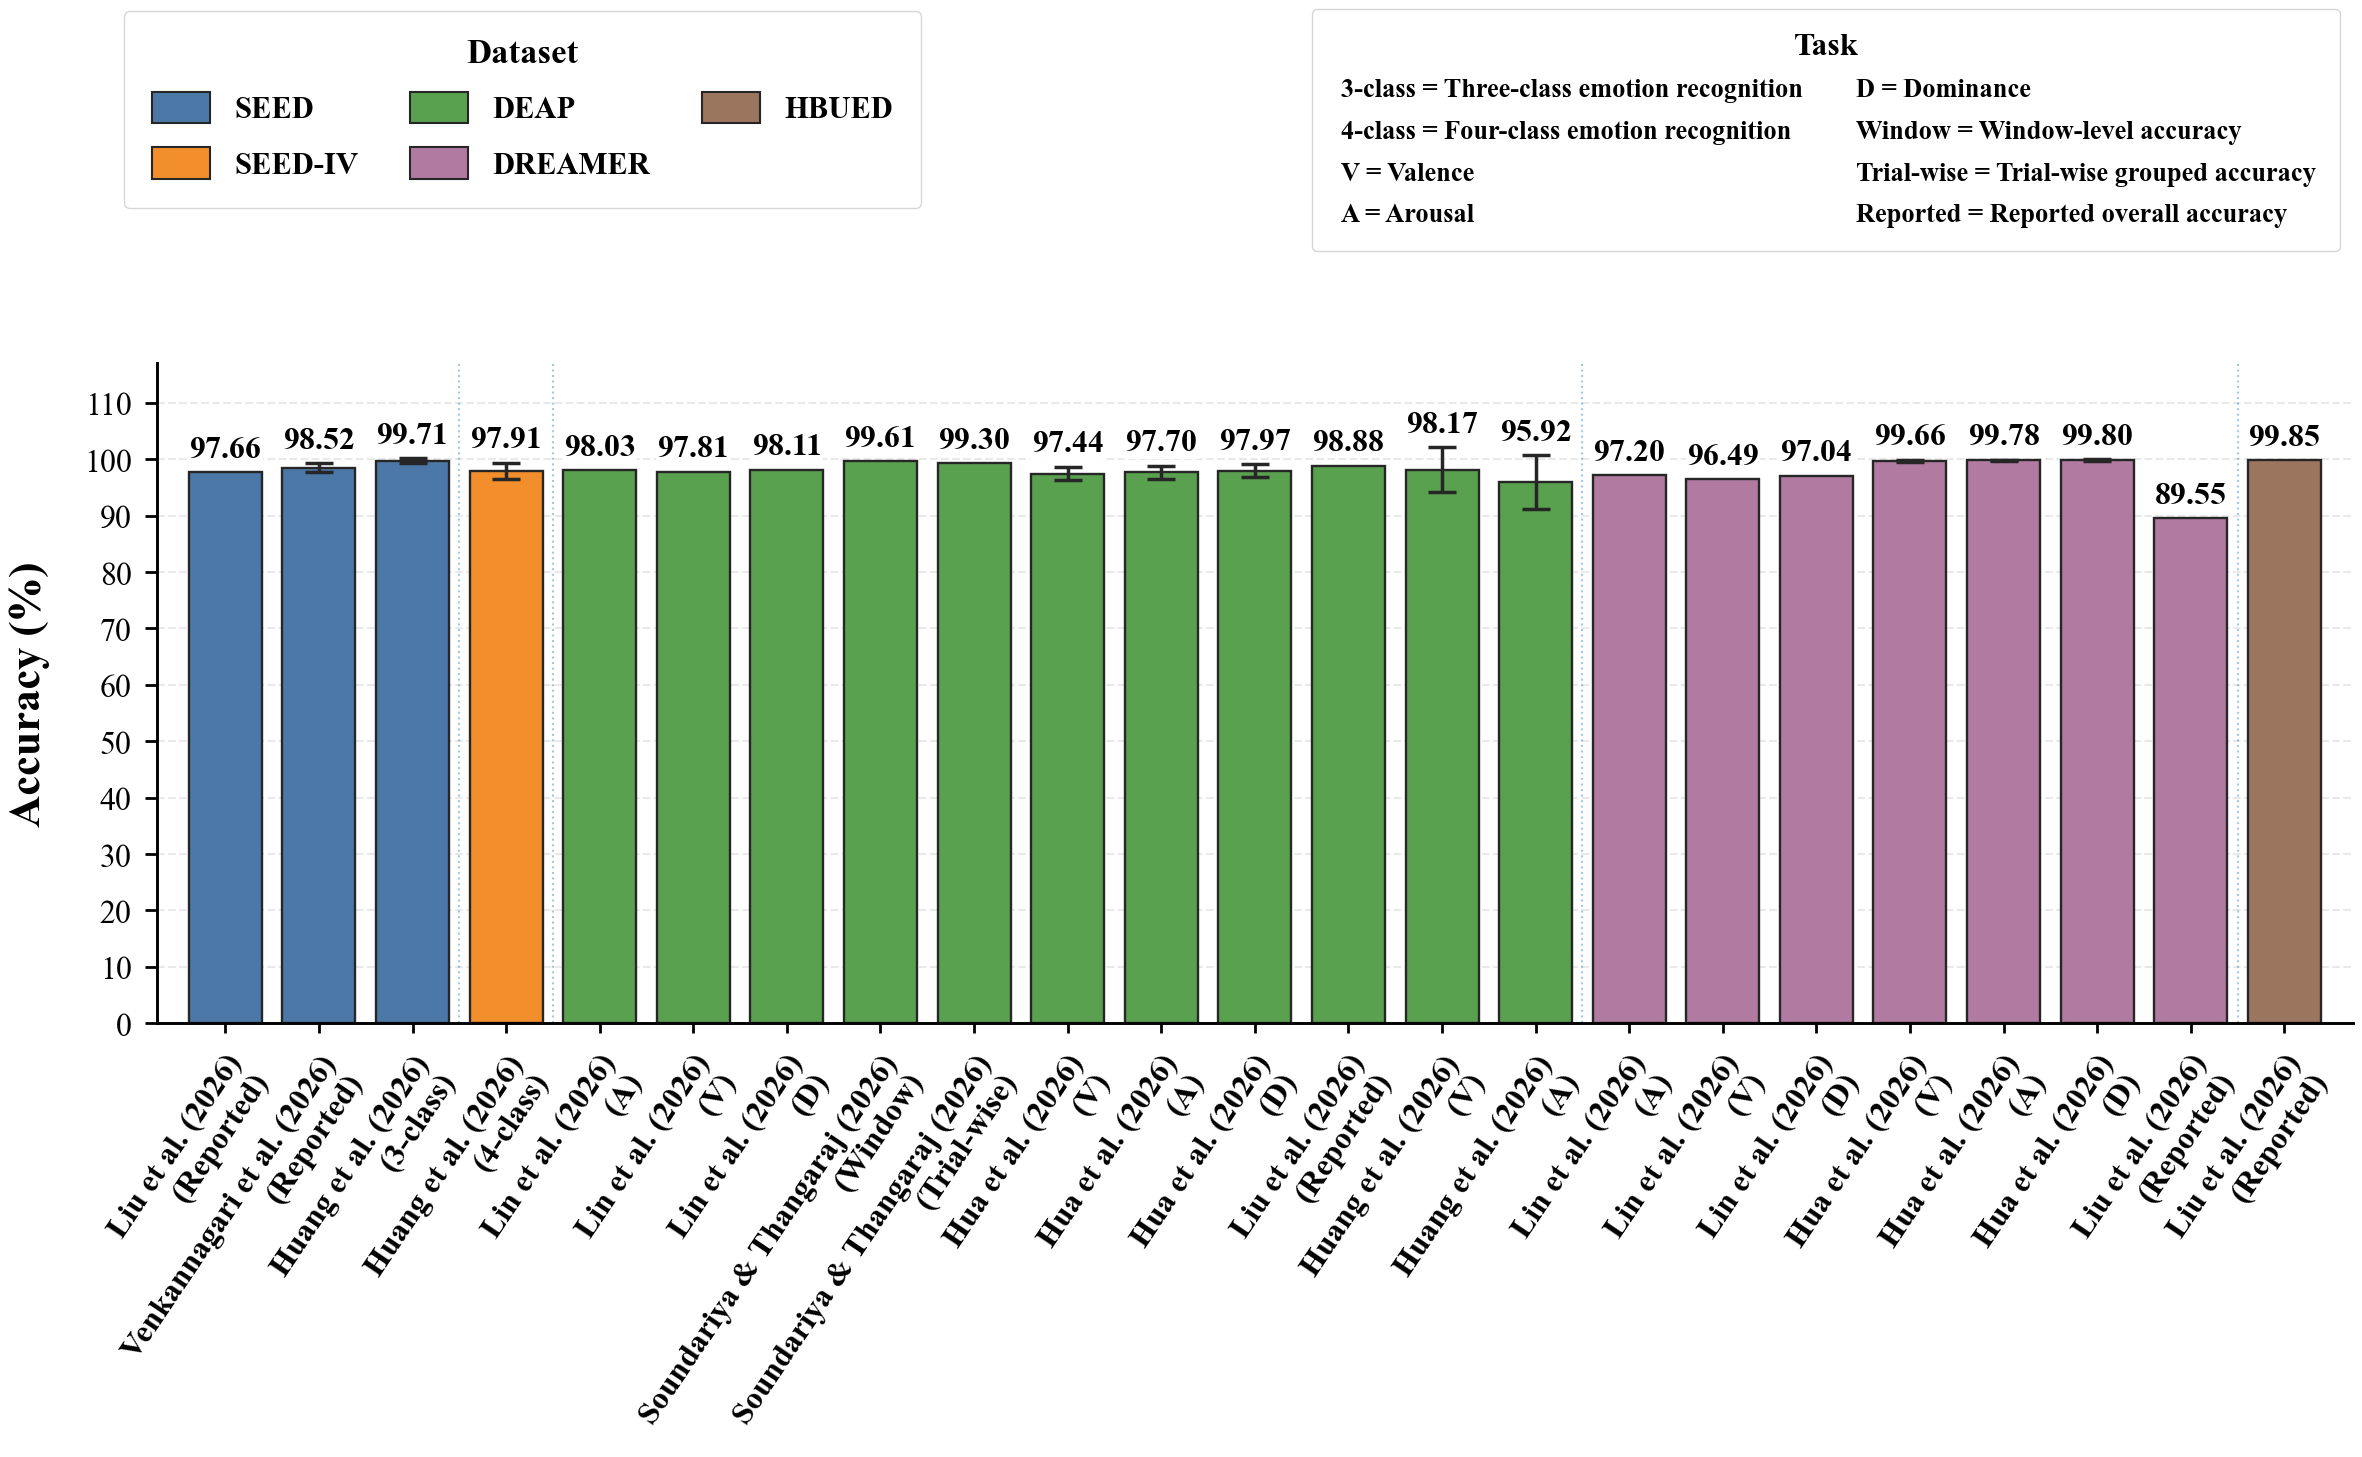

In [5]:
import os
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

papers = [
    {
        "study": "Lin et al.",
        "year": 2026,
        "model": "PconvCapsNet",
        "scores": [
            ("DEAP", "A", 98.03, None),
            ("DEAP", "V", 97.81, None),
            ("DEAP", "D", 98.11, None),
            ("DREAMER", "A", 97.20, None),
            ("DREAMER", "V", 96.49, None),
            ("DREAMER", "D", 97.04, None),
        ],
    },
    {
        "study": "Soundariya & Thangaraj",
        "year": 2026,
        "model": "AWT-Net",
        "scores": [
            ("DEAP", "Window", 99.61, None),
            ("DEAP", "Trial-wise", 99.30, None),
        ],
    },
    {
        "study": "Hua et al.",
        "year": 2026,
        "model": "BRAD-Net",
        "scores": [
            ("DEAP", "V", 97.44, 1.19),
            ("DEAP", "A", 97.70, 1.13),
            ("DEAP", "D", 97.97, 1.14),
            ("DREAMER", "V", 99.66, 0.22),
            ("DREAMER", "A", 99.78, 0.14),
            ("DREAMER", "D", 99.80, 0.16),
        ],
    },
    {
        "study": "Liu et al.",
        "year": 2026,
        "model": "TaFormer",
        "scores": [
            ("DEAP", "Reported", 98.88, None),
            ("SEED", "Reported", 97.66, None),
            ("DREAMER", "Reported", 89.55, None),
            ("HBUED", "Reported", 99.85, None),
        ],
    },
    {
        "study": "Venkannagari et al.",
        "year": 2026,
        "model": "Robust EEG",
        "scores": [("SEED", "Reported", 98.52, 0.79)],
    },
    {
        "study": "Huang et al.",
        "year": 2026,
        "model": "AST-CLNet",
        "scores": [
            ("SEED", "3-class", 99.71, 0.45),
            ("SEED-IV", "4-class", 97.91, 1.49),
            ("DEAP", "V", 98.17, 3.91),
            ("DEAP", "A", 95.92, 4.81),
        ],
    },
]

results = [
    {
        "study": paper["study"],
        "year": paper["year"],
        "model": paper["model"],
        "dataset": dataset,
        "task": task,
        "acc": acc,
        "std": std,
    }
    for paper in papers
    for dataset, task, acc, std in paper["scores"]
]
assert len(papers) == 6
assert len(results) == 23

dataset_order = ["SEED", "SEED-IV", "DEAP", "DREAMER", "HBUED"]
dataset_colors = {
    "SEED": "#4C78A8",
    "SEED-IV": "#F28E2B",
    "DEAP": "#59A14F",
    "DREAMER": "#B07AA1",
    "HBUED": "#9C755F",
}
ordered_results = [
    item for dataset in dataset_order for item in results if item["dataset"] == dataset
]
x_positions = np.arange(len(ordered_results))
accuracy = np.array([r["acc"] for r in ordered_results], dtype=float)
colors = [dataset_colors[r["dataset"]] for r in ordered_results]
labels = [f'{r["study"]} ({r["year"]})\n({r["task"]})' for r in ordered_results]

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "font.size": 23,
        "axes.labelsize": 23,
        "xtick.labelsize": 23,
        "ytick.labelsize": 23,
        "legend.fontsize": 23,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

fig, ax = plt.subplots(figsize=(24, 15))
bars = ax.bar(
    x_positions,
    accuracy,
    width=0.78,
    color=colors,
    edgecolor="0.15",
    linewidth=1.7,
)

# Display error bars only where the original study reported a standard deviation.
known_std = [i for i, r in enumerate(ordered_results) if r["std"] is not None]
ax.errorbar(
    x_positions[known_std],
    accuracy[known_std],
    yerr=[ordered_results[i]["std"] for i in known_std],
    fmt="none",
    capsize=10,
    elinewidth=2.5,
    ecolor="0.15",
    capthick=2.5,
    zorder=4,
)

ax.set_xticks(x_positions)
ax.set_xticklabels(
    labels,
    rotation=56,
    ha="right",
    rotation_mode="anchor",
    fontsize=23,
    fontweight="bold",
    linespacing=1.18,
)
ax.set_ylabel("Accuracy (%)", fontsize=32, fontweight="bold", labelpad=24)
ax.set_ylim(0, 117)
ax.set_yticks(np.arange(0, 111, 10))
ax.yaxis.grid(True, linestyle="--", linewidth=1.5, alpha=0.28)
ax.xaxis.grid(False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.1)
ax.spines["bottom"].set_linewidth(2.1)

for bar, record in zip(bars, ordered_results):
    error = record["std"] if record["std"] is not None else 0.0
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        record["acc"] + error + 1.5,
        f'{record["acc"]:.2f}',
        ha="center",
        va="bottom",
        fontsize=23,
        fontweight="bold",
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.0, "alpha": 0.97},
        zorder=10,
        clip_on=False,
    )

dataset_legend = fig.legend(
    handles=[
        Patch(facecolor=dataset_colors[d], edgecolor="0.15", linewidth=1.5, label=d)
        for d in dataset_order
    ],
    title="Dataset",
    loc="upper left",
    bbox_to_anchor=(0.055, 0.985),
    ncol=3,
    frameon=True,
    prop={"size": 22, "weight": "bold"},
    borderpad=0.9,
    handlelength=1.9,
    handleheight=1.2,
    columnspacing=1.7,
    labelspacing=0.75,
)
dataset_legend.get_title().set_fontsize(25)
dataset_legend.get_title().set_fontweight("bold")

task_legend_labels = [
    "3-class = Three-class emotion recognition",
    "4-class = Four-class emotion recognition",
    "V = Valence",
    "A = Arousal",
    "D = Dominance",
    "Window = Window-level accuracy",
    "Trial-wise = Trial-wise grouped accuracy",
    "Reported = Reported overall accuracy",
]
task_legend = fig.legend(
    handles=[
        Line2D([], [], linestyle="none", marker="", label=t) for t in task_legend_labels
    ],
    title="Task",
    loc="upper right",
    bbox_to_anchor=(0.99, 0.985),
    ncol=2,
    frameon=True,
    prop={"size": 19, "weight": "bold"},
    borderpad=0.9,
    handlelength=0,
    handletextpad=0.2,
    columnspacing=1.8,
    labelspacing=0.65,
)
task_legend.get_title().set_fontsize(23)
task_legend.get_title().set_fontweight("bold")

ax.tick_params(axis="y", labelsize=23, width=2.0, length=9, pad=9)
ax.tick_params(axis="x", labelsize=23, width=2.0, length=7, pad=12)

current_position = 0
for dataset in dataset_order[:-1]:
    current_position += sum(r["dataset"] == dataset for r in ordered_results)
    ax.axvline(current_position - 0.5, linewidth=1.5, linestyle=":", alpha=0.4)

ax.margins(x=0.015)
plt.subplots_adjust(left=0.075, right=0.99, top=0.74, bottom=0.30)

filename = "subject_dependent_6_studies"
plt.savefig(f"{filename}.pdf", bbox_inches="tight", pad_inches=0.20)
raster_dpi = int(os.environ.get("RASTER_DPI", "300"))
plt.savefig(f"{filename}.png", dpi=raster_dpi, bbox_inches="tight", pad_inches=0.20)
if os.environ.get("SKIP_TIFF") != "1":
    plt.savefig(
        f"{filename}.tiff", dpi=raster_dpi, bbox_inches="tight", pad_inches=0.20
    )
plt.show()